# 05b N3 vs N2 within the same hour

Reads `data/derived/features_all35.csv` (notebook 05).

Question: is N3's higher heart rate and lower RMSSD/HF (notebook 05) a stage effect, or because N3 sits early in the night? Compare N3 with N2 only inside the same hour of the same person, using raw (unscaled) features and passing epochs only.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = PROJECT / "notebooks" / "figs"
plt.rcParams.update({"font.size": 8})
F = pd.read_csv(PROJECT / "data" / "derived" / "features_all35.csv")
F = F[F["pass"]].copy()
F["log_hf"] = np.log(F.hf); F["log_lf"] = np.log(F.lf)
F["hour"] = np.floor((F.t_start - F.groupby("subject").t_start.transform("min")) / 3600).astype(int)
FE = ["hr_mean", "rmssd_ms", "log_hf", "log_lf"]

In [2]:
# LOGIC: per person, per hour from their first scored epoch: if the hour has at least
#   min_n passing N3 epochs and min_n passing N2 epochs, take N3 median minus N2 median
#   for each feature. Per person: median over such hours. Also the naive whole-night
#   difference (no hour matching) for the same people, for contrast.
# EDGE CASES: people with no hour holding both stages are left out (counted).
# NOT HANDLED: neighbouring epochs are not independent; no p-values are given.
# CHECKED BY: printed counts of people and hours used.
min_n = 3
rows, hrs = [], []
for s, g in F.groupby("subject"):
    for h, gh in g.groupby("hour"):
        a, b = gh[gh.stage5 == "N3"], gh[gh.stage5 == "N2"]
        if len(a) >= min_n and len(b) >= min_n:
            hrs.append({"subject": s, "hour": h, "n3": len(a), "n2": len(b),
                        **{f: a[f].median() - b[f].median() for f in FE}})
    a, b = g[g.stage5 == "N3"], g[g.stage5 == "N2"]
    if len(a) >= min_n and len(b) >= min_n:
        rows.append({"subject": s, **{f: a[f].median() - b[f].median() for f in FE}})
H = pd.DataFrame(hrs); naive = pd.DataFrame(rows).set_index("subject")
within = H.groupby("subject")[FE].median()
print(f"people with N3: {F[F.stage5 == 'N3'].subject.nunique()}; with at least one matched hour: {len(within)}; matched hours: {len(H)}")
print("N3 hours by hour of night:", H.hour.value_counts().sort_index().to_dict())
summ = pd.DataFrame({"within_hour_median": within.median(), "n_people_N3_lower": (within < 0).sum(),
                     "naive_median": naive.loc[within.index].median(), "naive_n_lower": (naive.loc[within.index] < 0).sum()})
print(summ.round(3).to_string())
print(within.round(2).to_string())

people with N3: 16; with at least one matched hour: 11; matched hours: 28
N3 hours by hour of night: {0: 7, 1: 7, 2: 7, 3: 2, 4: 1, 5: 2, 6: 2}
          within_hour_median  n_people_N3_lower  naive_median  naive_n_lower
hr_mean                0.926                  3         2.136              5
rmssd_ms              -4.639                  8       -14.818              8
log_hf                -0.153                  8        -0.593              7
log_lf                -0.459                 11        -0.692             11
         hr_mean  rmssd_ms  log_hf  log_lf
subject                                   
S006       -1.70      6.13   -0.04   -0.14
S013        1.01     -4.64   -0.18   -0.46
S014        0.93     -3.83    0.08   -0.43
S015        5.36    -28.93   -0.70   -0.46
S030        0.97     -4.13   -0.03   -0.26
S042        1.25     -4.84   -0.15   -0.19
S061       -0.98     -5.01   -0.64   -0.60
S096        0.50    -27.02   -0.60   -1.86
S097        2.54    -16.33    0.02   -0.7

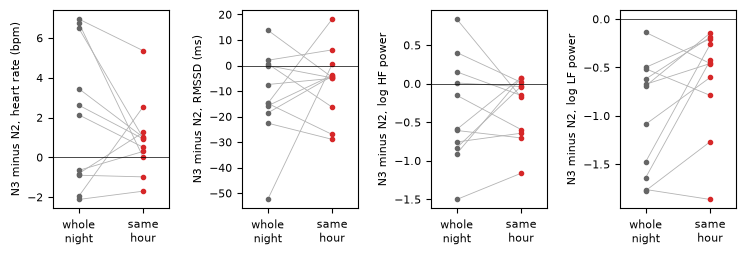

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(7.5, 2.6))
labs = {"hr_mean": "heart rate (bpm)", "rmssd_ms": "RMSSD (ms)", "log_hf": "log HF power", "log_lf": "log LF power"}
for ax, f in zip(axes, FE):
    x0 = naive.loc[within.index, f]; x1 = within[f]
    for v0, v1 in zip(x0, x1):
        ax.plot([0, 1], [v0, v1], color="0.7", lw=0.6)
    ax.plot(np.zeros(len(x0)), x0, "o", ms=3, color="0.4"); ax.plot(np.ones(len(x1)), x1, "o", ms=3, color="tab:red")
    ax.axhline(0, color="k", lw=0.5); ax.set_xticks([0, 1]); ax.set_xticklabels(["whole\nnight", "same\nhour"])
    ax.set_xlim(-0.4, 1.4); ax.set_ylabel(f"N3 minus N2, {labs[f]}")
fig.tight_layout(); fig.savefig(FIG_DIR / "fig_n3_vs_n2_same_hour.png", dpi=150); plt.show()